# 04 — Yolculuk Süresi Tahmini: PySpark MLlib vs scikit-learn (Öğrenci 4)

**Soru:** Aynı veri, aynı özellikler ve aynı hiperparametrelerle eğitildiğinde dağıtık (PySpark MLlib) ve klasik (scikit-learn) yaklaşım doğruluk, süre ve bellek açısından nasıl ayrışır? Veri büyüdükçe bu tablo nasıl değişir?

| | |
|---|---|
| Veri | `data/clean` — 17.210.961 temiz kayıt → 100K / 1M / 5M örneklem + tamamı (17M) (S1'in xxhash64 anahtarı, iç içe) |
| Hedef | `trip_duration_min` ∈ (1, 180] dk |
| Modeller | OLS (`LinearRegression`) ve gradyan artırma (Spark `GBTRegressor` / sklearn `HistGradientBoostingRegressor`) |
| Adillik | Aynı satırlar, aynı train/test ayrımı, aynı özellikler (bölge dahil), aynı hiperparametreler; her ölçüm ayrı süreçte, bellek = süreç ağacının (JVM dahil) tepe RSS'i |

Deneyin tamamı `python -m src.ml_duration` (~30 dk) ve `python -m src.ml_analysis` (~5 dk) ile çalışır. Bu notebook kayıtlı sonuçları yorumlar ve adilliği 100K örneklemde canlı doğrular.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display
from src import ml_duration as ml
pd.set_option("display.width", 160)
print("Sayısal özellikler:", ml.NUMERIC_FEATURES)
print("Bölge kolonları   :", ml.LOCATION_COLS, "→", ml.CATEGORICAL_FEATURES, f"({ml.N_LOCATION_CODES} kod)")
print(f"GBT: {ml.GBT_MAX_ITER} ağaç, derinlik {ml.GBT_MAX_DEPTH}, öğrenme oranı {ml.GBT_LEARNING_RATE}, yaprakta ≥{ml.GBT_MIN_LEAF}")

Sayısal özellikler: ['trip_distance', 'pickup_hour', 'pickup_dow', 'extra', 'mta_tax', 'tolls_amount', 'improvement_surcharge', 'cbd_congestion_fee']
Bölge kolonları   : ['PULocationID', 'DOLocationID'] → ['PU_code', 'DO_code'] (255 kod)
GBT: 50 ağaç, derinlik 5, öğrenme oranı 0.1, yaprakta ≥20


## 1. Özellik seçimi

| Dışlanan kolon | Neden |
|---|---|
| `fare_amount`, `total_amount`, `tip_amount` | Yolculuk bittikten sonra hesaplanır (sürenin fonksiyonu) → leakage |
| `tpep_dropoff_datetime` | Hedefin kendisinden türetilir → doğrudan leakage |
| `passenger_count`, `RatecodeID`, `store_and_fwd_flag`, `congestion_surcharge`, `Airport_fee` | Flex Fare kayıtlarında (%25,5) kasıtlı null. `dropna()` bu kayıtları silerdi. |

**Sızıntı kontrolü:** `tolls_amount` ve `cbd_congestion_fee` yolculuk sonunda kesinleşir. Çıkarıldıklarında doğruluk düşmüyor (§5).

**Bölge kodlaması:** Kodlar yalnızca eğitim kümesinden öğrenilir. En sık 254 bölge 0…253 kodunu alır; kalanlar ve görülmeyenler 254 ("diğer") olur. Bu sınır sklearn HistGradientBoosting'in kategorik özellik sınırından (≤ 255) gelir. Aynı kodlar iki çerçeveye de verilir.

## 2. Adillik kontrolü (canlı, 100K örneklem)

Aynı örneklem dosyası iki çerçeveye veriliyor. OLS'nin tek bir çözümü olduğu için iki çerçeve **aynı tahmini** vermeli; vermiyorsa karşılaştırma adil değildir.

In [2]:
from pyspark.sql import functions as F
from src.spark_session import get_spark

sample_dir = ml.SAMPLES_DIR / "100K"
spark = get_spark(app_name="s4-notebook")
sdf = ml.with_nominal_metadata(spark.read.parquet(str(sample_dir)))
train = sdf.filter(F.col(ml.SPLIT_COL)).drop(ml.SPLIT_COL)
test = sdf.filter(~F.col(ml.SPLIT_COL)).drop(ml.SPLIT_COL)
spark_metrics = ml._evaluate(ml._build_pipeline("lr").fit(train).transform(test))

pdf = pd.read_parquet(sample_dir)
for c in ml.CATEGORICAL_FEATURES:
    pdf[c] = pdf[c].astype("int64")
X = pdf[ml.NUMERIC_FEATURES + ml.CATEGORICAL_FEATURES]; y = pdf[ml.TARGET_COL]; m = pdf[ml.SPLIT_COL]
sk_model = ml.build_sklearn_model("lr").fit(X[m], y[m])
sk_metrics = ml.sklearn_metrics(y[~m], sk_model.predict(X[~m]))
spark.stop()

check = pd.DataFrame([spark_metrics, sk_metrics], index=["PySpark", "scikit-learn"]).round(4)
check

,rmse,mae,r2
PySpark,7.2018,4.9090,0.6427
scikit-learn,7.2007,4.9089,0.6428


## 3. Sonuçlar (16 ölçüm)

In [3]:
comparison, importance, pred = ml.load_saved()
cols = ["framework", "model", "size_label", "n_train", "rmse", "mae", "r2", "train_time_s", "predict_time_s", "peak_rss_mb", "peak_jvm_mb"]
comparison[cols]

,framework,model,size_label,n_train,rmse,mae,r2,train_time_s,predict_time_s,peak_rss_mb,peak_jvm_mb
0,PySpark,LinearRegression,100K,79549,7.2018,4.9090,0.6427,4.069,0.488,958.5,866.0
1,PySpark,GBTRegressor,100K,79549,5.9628,3.8043,0.7551,103.433,0.523,2483.7,2391.0
2,scikit-learn,LinearRegression,100K,79549,7.2007,4.9089,0.6428,0.494,0.010,209.9,NaN
3,scikit-learn,HistGradientBoosting,100K,79549,5.7137,3.6866,0.7751,0.203,0.018,212.1,NaN
4,PySpark,LinearRegression,1M,798285,7.1697,4.9238,0.6476,4.471,0.696,2123.5,2031.1
5,PySpark,GBTRegressor,1M,798285,5.5377,3.5769,0.7898,104.667,0.766,4615.2,4522.9
6,scikit-learn,LinearRegression,1M,798285,7.1700,4.9241,0.6475,6.856,0.092,745.9,NaN
7,scikit-learn,HistGradientBoosting,1M,798285,5.5712,3.6106,0.7872,1.129,0.215,553.4,NaN
8,PySpark,LinearRegression,5M,3997515,7.1754,4.9260,0.6473,5.959,1.374,3363.2,3270.8
9,PySpark,GBTRegressor,5M,3997515,5.4693,3.5510,0.7951,140.700,1.897,6159.3,6067.0


In [4]:
# Çerçeveler arası oranlar (aynı model ailesi, aynı boyut)
pairs = {"LinearRegression": ("LinearRegression", "LinearRegression"), "GBT": ("GBTRegressor", "HistGradientBoosting")}
rows = []
for family, (spark_m, sk_m) in pairs.items():
    for size in ml.SAMPLE_LABELS:
        s = comparison[(comparison.framework == "PySpark") & (comparison.model == spark_m) & (comparison.size_label == size)].iloc[0]
        k = comparison[(comparison.framework == "scikit-learn") & (comparison.model == sk_m) & (comparison.size_label == size)].iloc[0]
        rows.append({"aile": family, "boyut": size,
                     "süre oranı Spark/sklearn": round(s.train_time_s / k.train_time_s, 1),
                     "bellek oranı Spark/sklearn": round(s.peak_rss_mb / k.peak_rss_mb, 2),
                     "RMSE farkı (Spark − sklearn)": round(s.rmse - k.rmse, 3)})
pd.DataFrame(rows)

,aile,boyut,süre oranı Spark/sklearn,bellek oranı Spark/sklearn,RMSE farkı (Spark − sklearn)
0,LinearRegression,100K,8.2,4.57,0.001
1,LinearRegression,1M,0.7,2.85,-0.000
2,LinearRegression,5M,0.2,1.10,-0.001
3,LinearRegression,17M,0.1,0.56,-0.000
4,GBT,100K,509.5,11.71,0.249
5,GBT,1M,92.7,8.34,-0.034
6,GBT,5M,29.1,2.79,-0.092
7,GBT,17M,13.5,0.97,-0.088


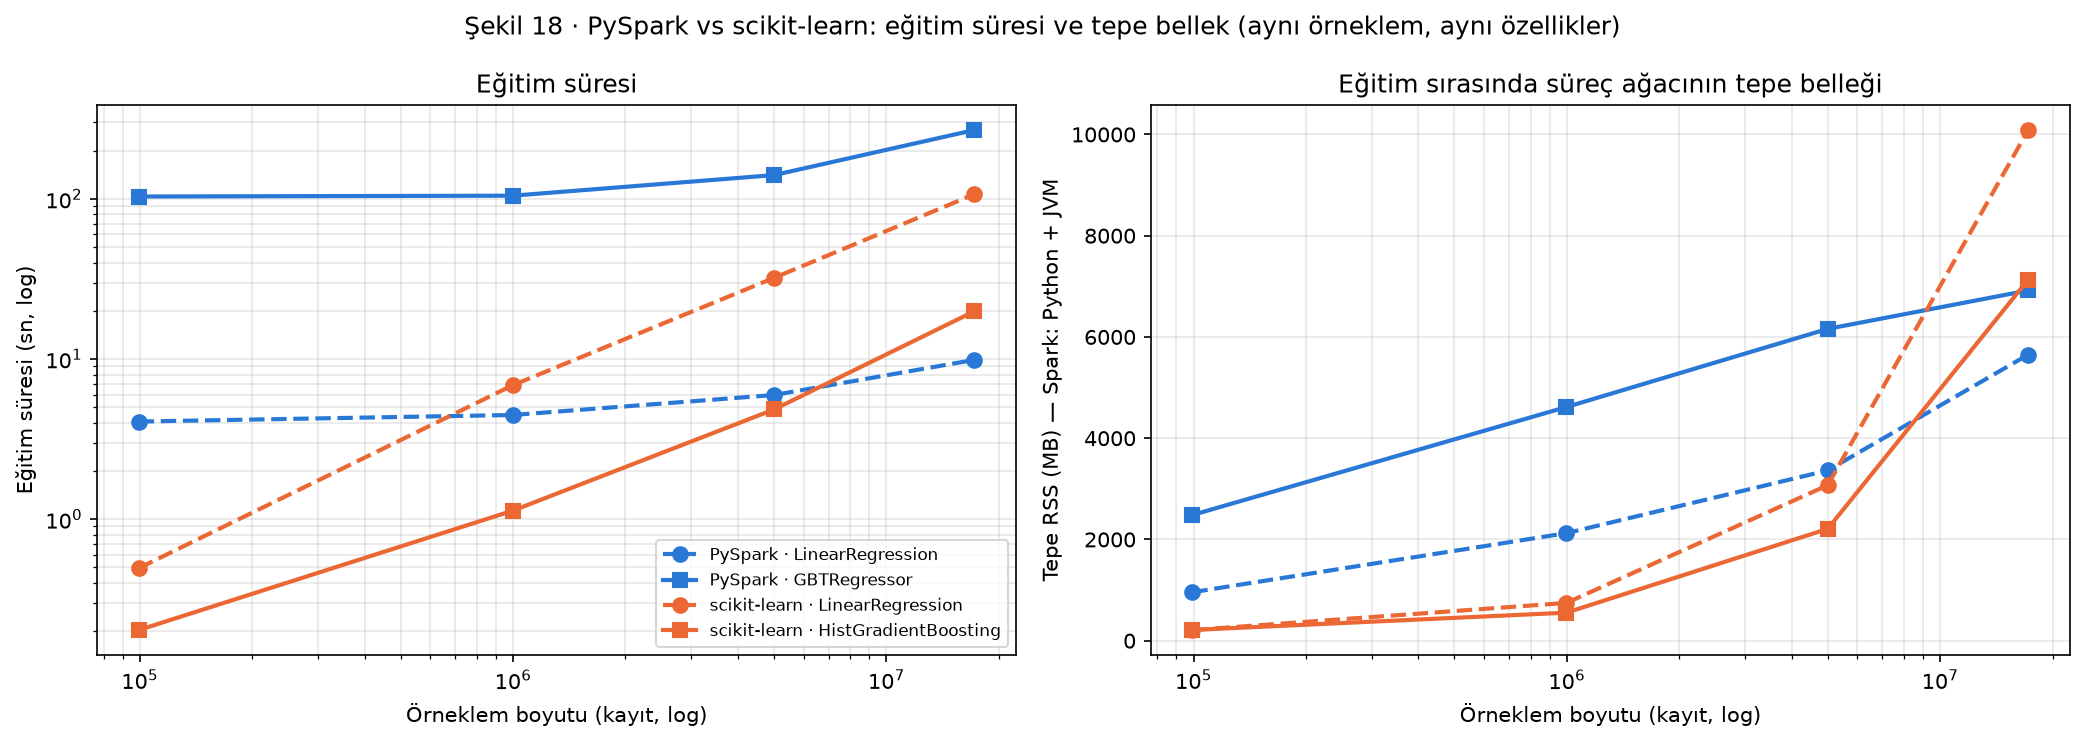

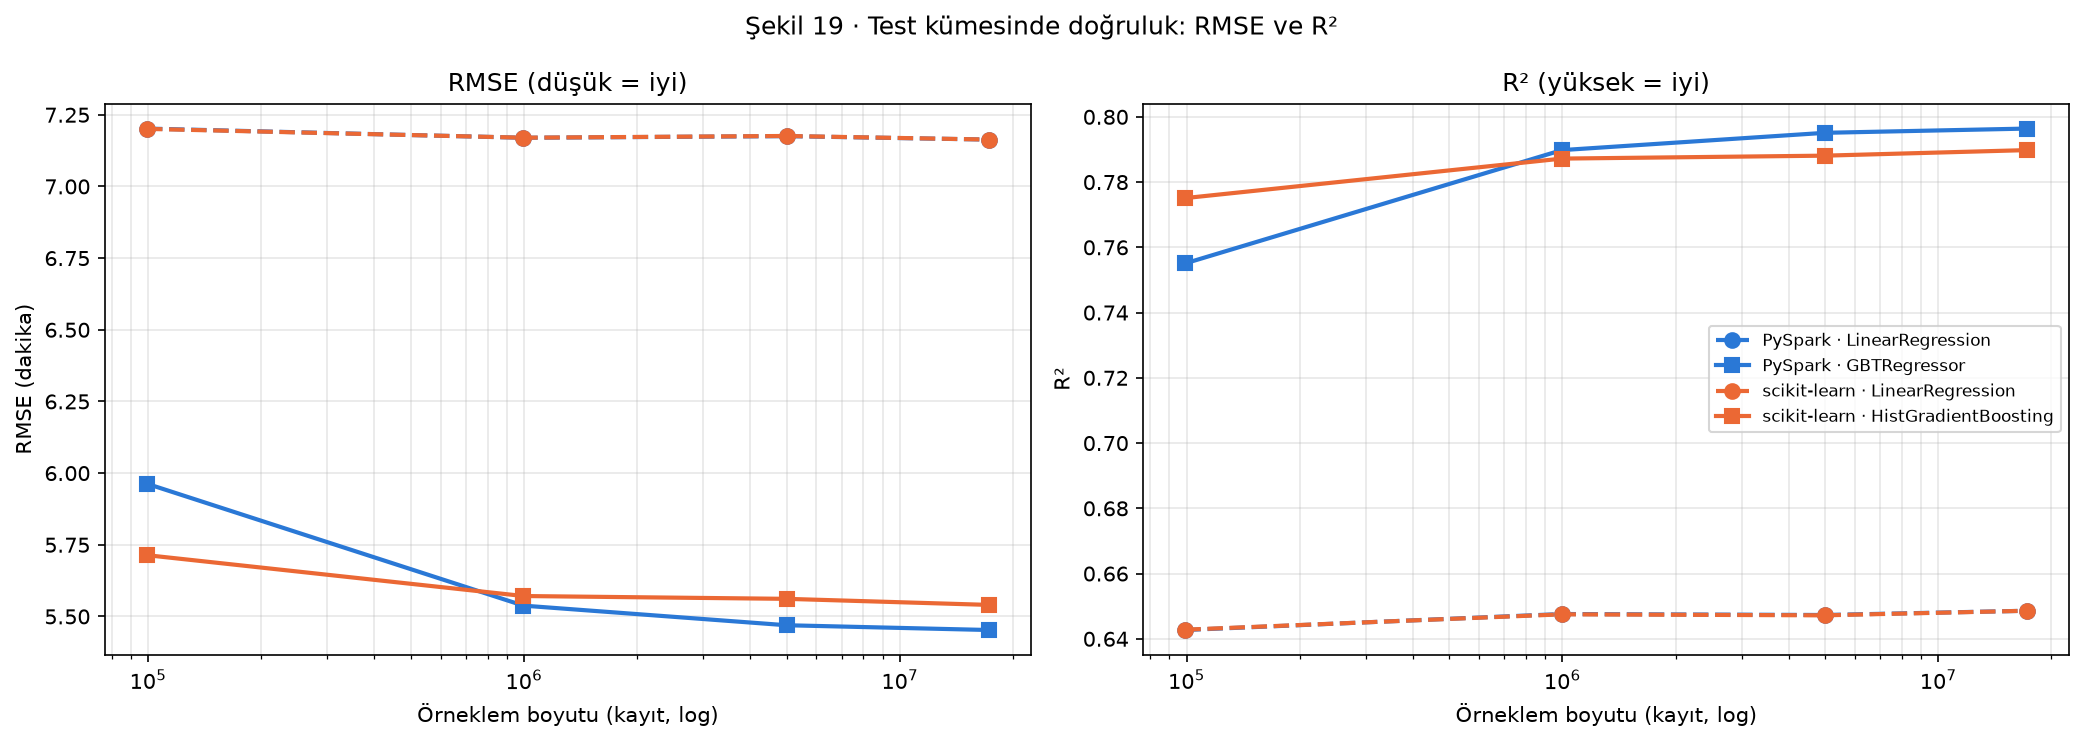

In [5]:
for f in ["18_s4_scalability.png", "19_s4_model_comparison.png"]:
    display(Image(filename=str(ml.FIGURES_DIR / f)))

## 4. Özellik önemi ve tahmin kalitesi (Spark GBT, 1M)

,feature,importance
0,trip_distance,0.468759
1,DOLocationID,0.181066
2,pickup_hour,0.131811
3,PULocationID,0.128512
4,pickup_dow,0.070701
5,cbd_congestion_fee,0.007616
6,tolls_amount,0.005325
7,improvement_surcharge,0.004900
8,extra,0.001234
9,mta_tax,0.000077


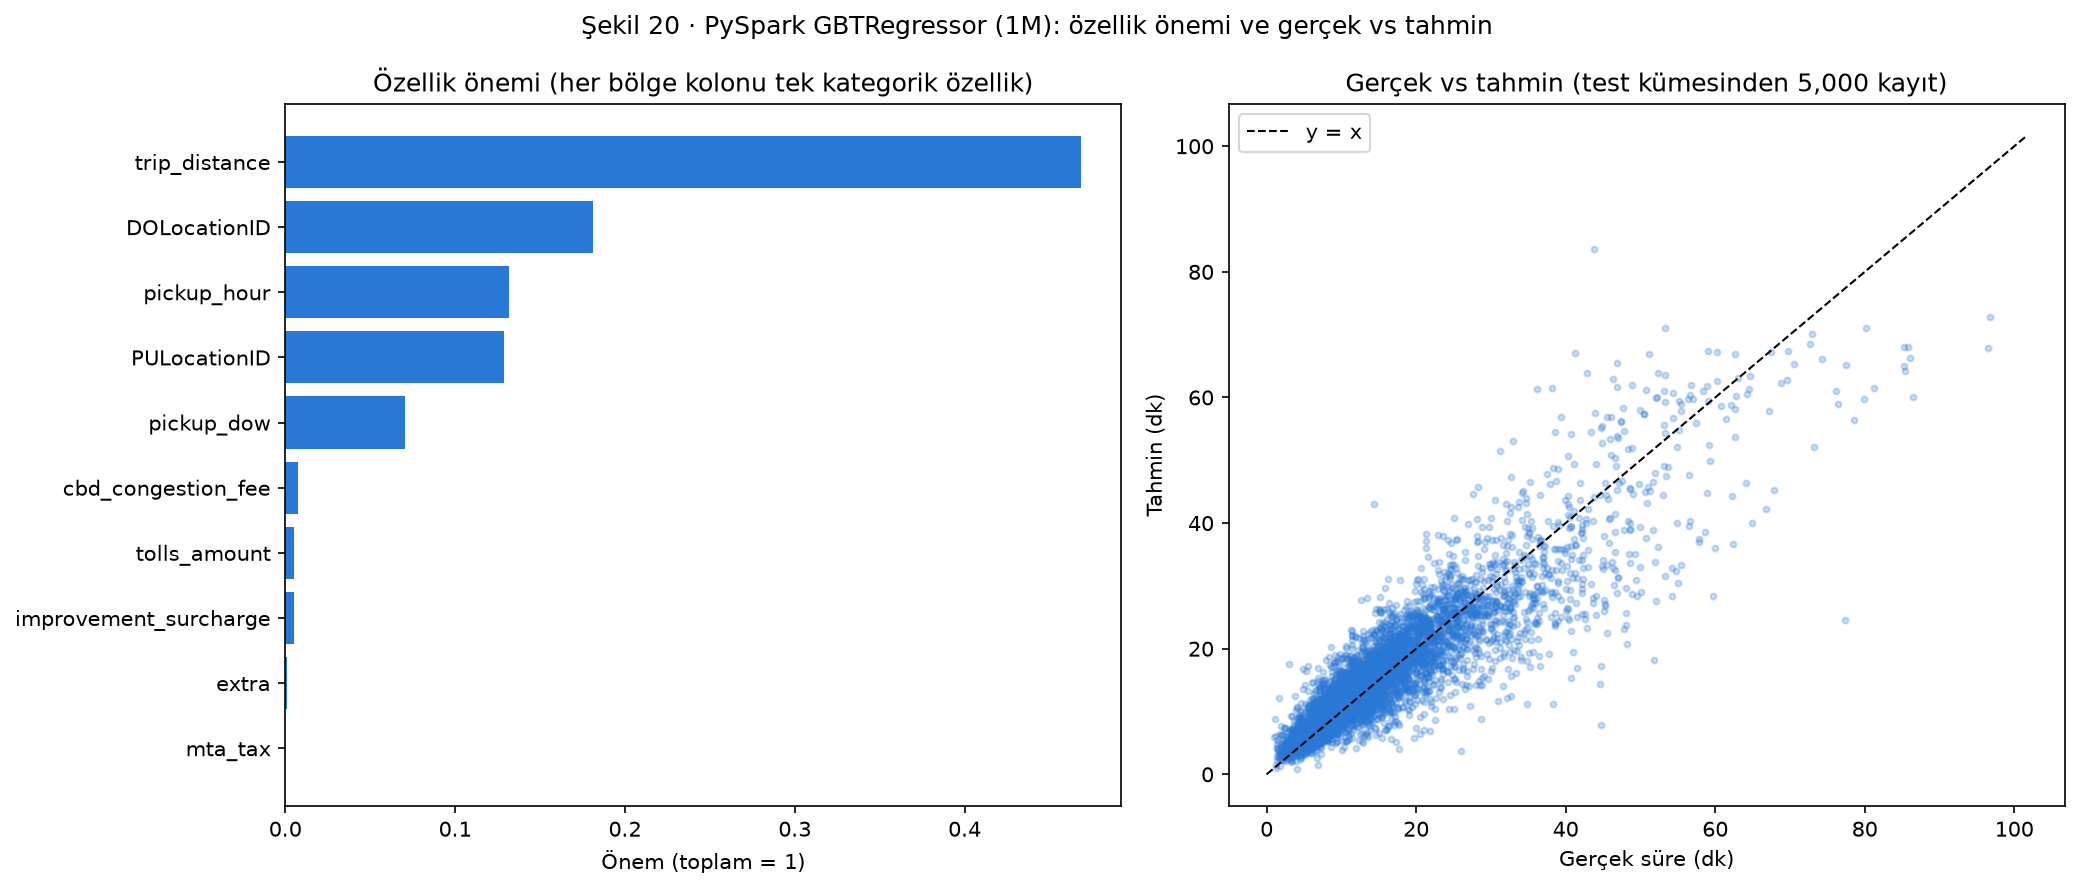

In [6]:
display(importance)
display(Image(filename=str(ml.FIGURES_DIR / "20_s4_feature_actual_pred.png")))

## 5. Ek analizler: sızıntı, hiperparametre araması, hata analizi

`src/ml_analysis.py`, scikit-learn HistGradientBoosting (Spark GBT'den 14–500× hızlı, ana deneyde 1M ve üzerinde RMSE farkı ≤ 0,1 dk). Arama ızgarası 12 ayar; seçim 1M eğitim kümesinden hash'le ayrılan %20 doğrulama payında yapılır, test kümesi yalnızca son modelde bir kez kullanılır.

,label,n_features,rmse,mae,r2
0,Tam (8 sayısal + bölgeler),10,5.5614,3.6037,0.7881
1,Biniş anı (ücret kalemleri yok),5,5.5361,3.5712,0.7900
2,Yalnız bölge + zaman (mesafe yok),4,6.9125,4.9120,0.6726


,max_iter,max_depth,learning_rate,stage,size_label,rmse,mae,r2,train_time_s
12,50,5.0,0.1,test_default,5M,5.5361,3.5712,0.7900,4.43
13,200,NaN,0.1,test_tuned,5M,5.0424,3.2011,0.8258,15.88
10,200,NaN,0.1,validation,1M,5.1298,3.2491,0.8202,3.46
8,200,8.0,0.1,validation,1M,5.1304,3.2404,0.8201,5.02
11,200,NaN,0.2,validation,1M,5.1368,3.2536,0.8197,3.21
9,200,8.0,0.2,validation,1M,5.1388,3.2508,0.8195,5.23
3,50,8.0,0.2,validation,1M,5.1964,3.2959,0.8155,1.46
7,200,5.0,0.2,validation,1M,5.2021,3.3140,0.8150,2.60
5,50,NaN,0.2,validation,1M,5.2053,3.3131,0.8148,1.08
6,200,5.0,0.1,validation,1M,5.2625,3.3573,0.8107,2.63


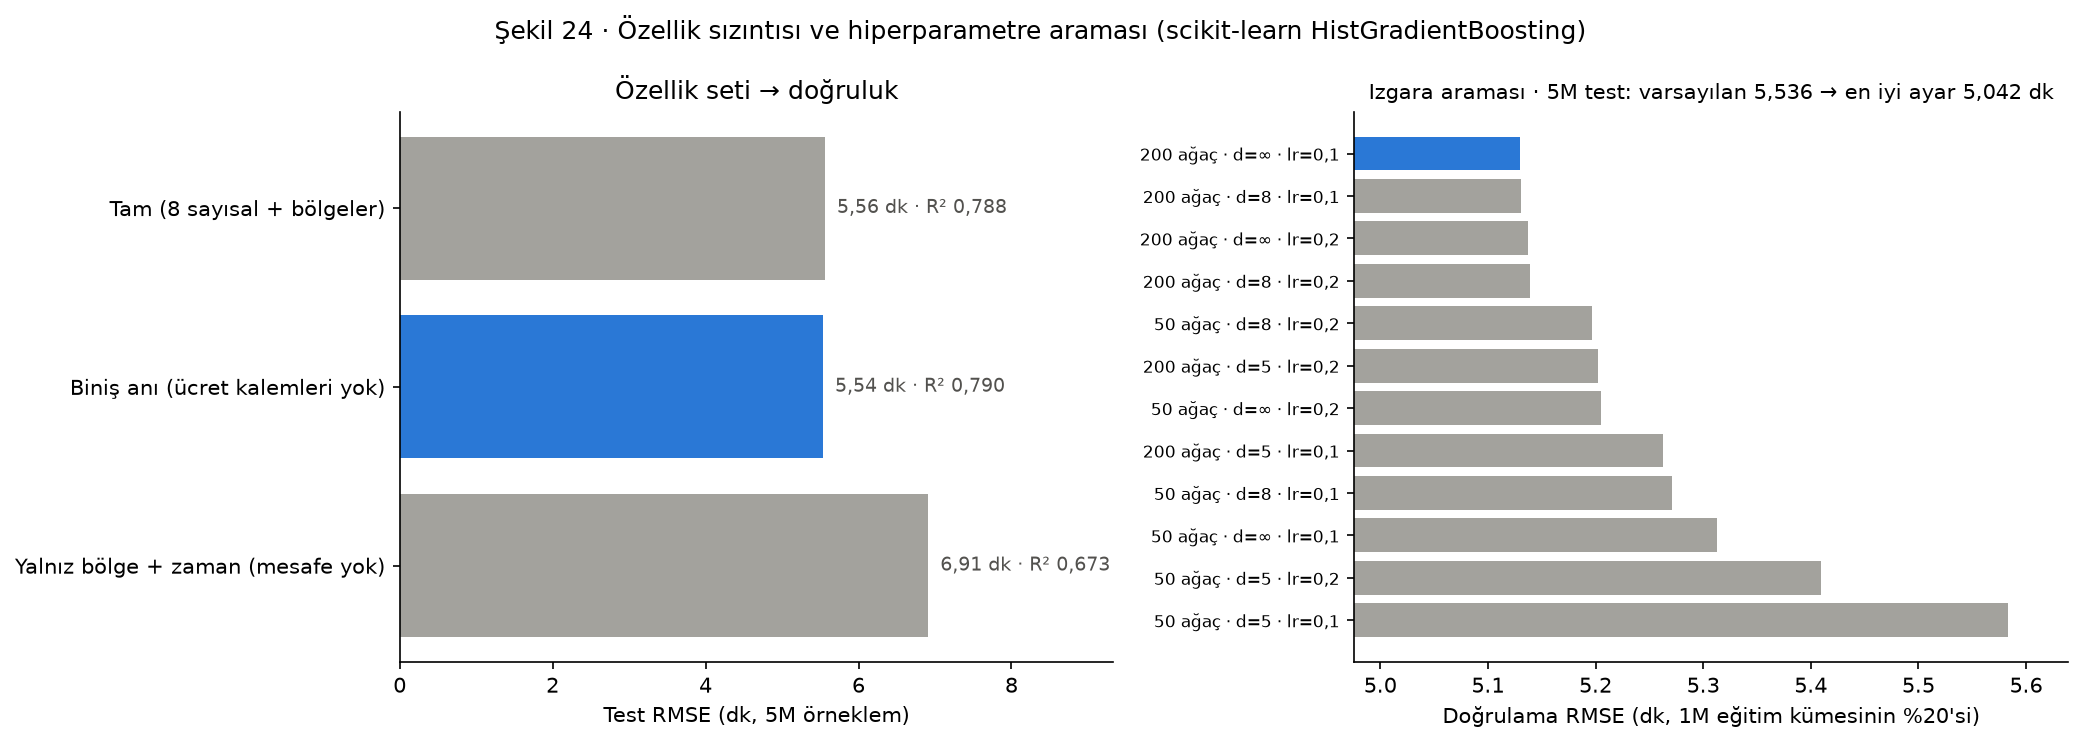

In [7]:
from src import ml_analysis as ma
ablation, tuning, errors = ma.load_saved()
display(ablation[["label", "n_features", "rmse", "mae", "r2"]])
display(tuning.sort_values(["stage", "rmse"]))
display(Image(filename=str(ml.FIGURES_DIR / "24_s4_ablation_tuning.png")))

,dimension,group,n,rmse,mae,bias,mean_true,mape_pct
0,distance_bin,0–1,218100,3.3130,2.0279,-0.0142,7.0436,28.7903
1,distance_bin,1–2,316186,3.7456,2.5203,0.0005,11.8213,21.3203
2,distance_bin,2–5,292071,4.9578,3.4296,0.0001,19.1133,17.9435
3,distance_bin,5–10,108753,6.9126,4.7336,0.0043,26.9728,17.5495
4,distance_bin,10–20,58198,9.5360,6.7292,0.1121,42.4914,15.8367
5,distance_bin,20+,6019,12.3067,8.5800,-0.3246,54.0372,15.8779
30,Borough,Bronx,4482,6.9708,4.4239,0.0491,20.9092,21.1575
31,Borough,Brooklyn,28575,6.0786,3.9499,-0.0076,22.5766,17.4957
32,Borough,EWR,5,17.7919,13.1570,-1.2071,20.9000,62.9522
33,Borough,Manhattan,883672,4.5468,2.9397,0.0007,14.7844,19.8837


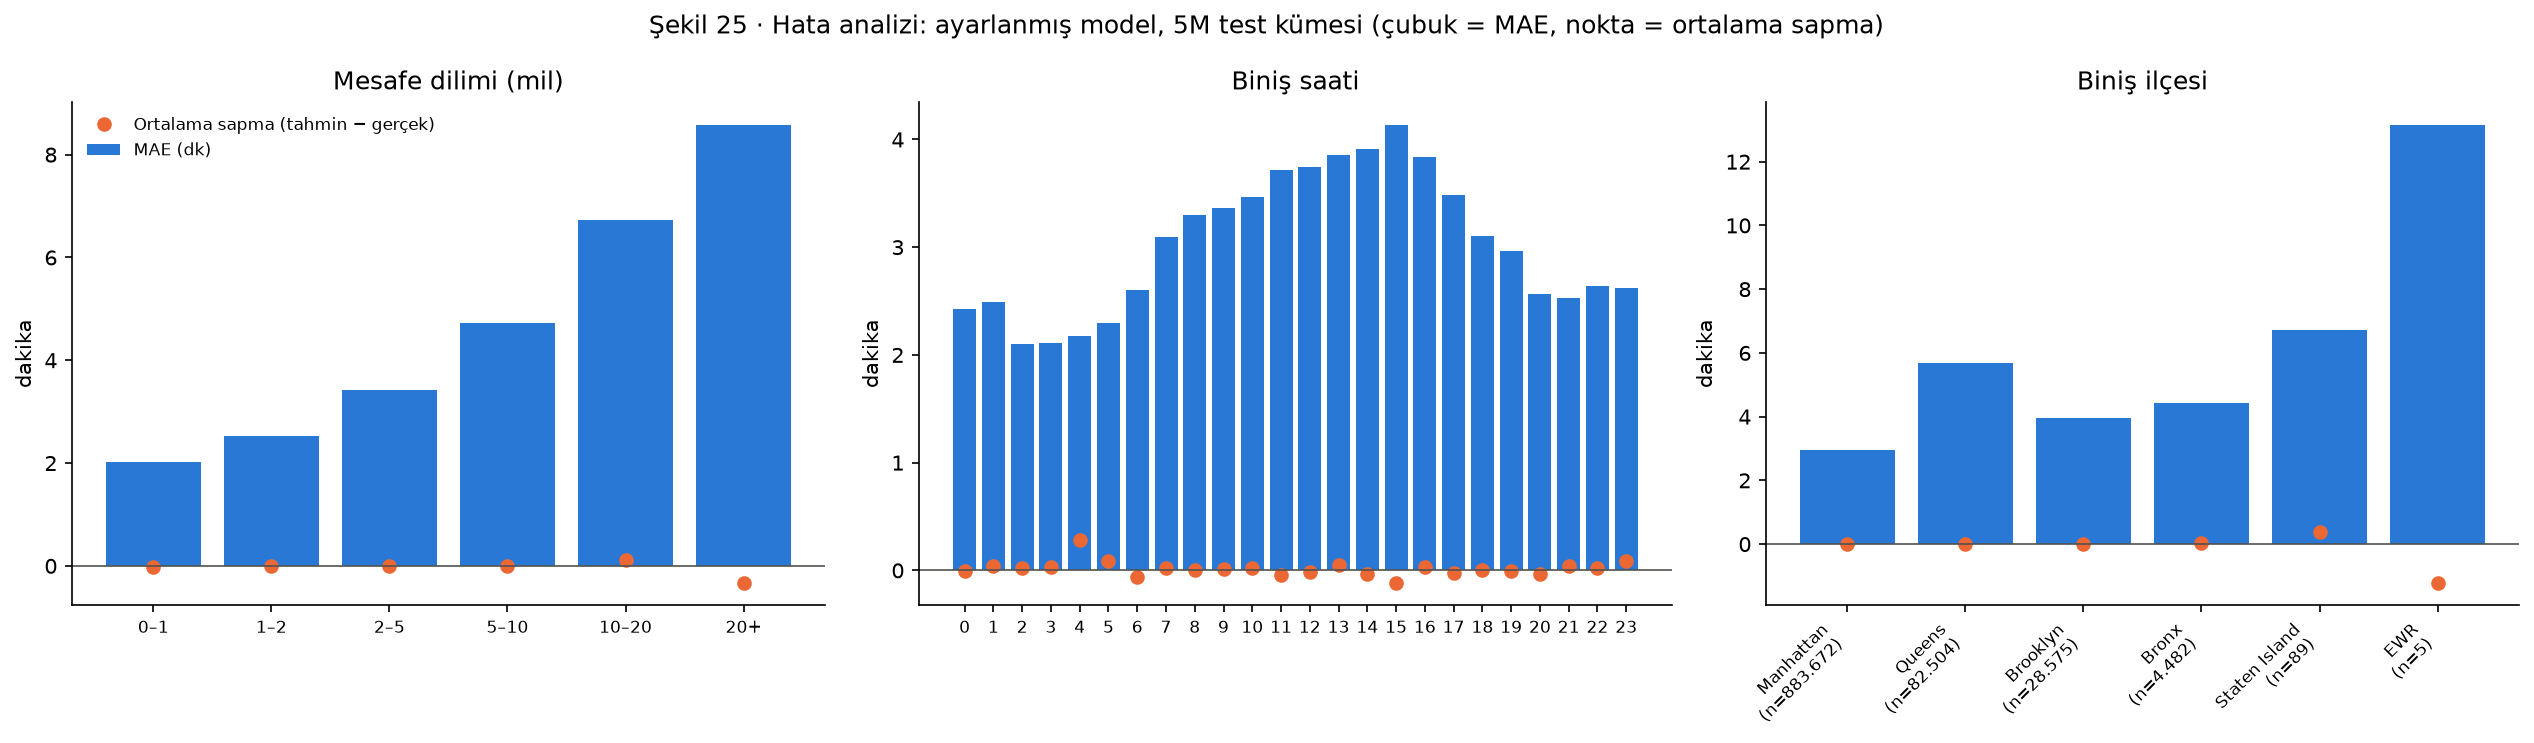

In [8]:
display(errors[errors["dimension"] != "pickup_hour"])
display(Image(filename=str(ml.FIGURES_DIR / "25_s4_error_analysis.png")))

## 6. Yorum — neden böyle?

- **Adillik:** OLS iki çerçevede aynı sonucu veriyor (§2 ve dört boyutta RMSE farkı ≤ 0,002). Kalan farklar algoritma uygulamasından geliyor.
- **GBT, OLS'den ~%24 daha iyi.** Süre mesafeyle doğrusal artmıyor. Bölge ve saat etkileşimleri (Manhattan içi yoğun saat, havalimanı otoyolu) ağaç bölmeleriyle yakalanıyor. Bölgelerin toplam önemi (~0,31), saat ve günün toplamından (~0,20) büyük.
- **Veri büyüdükçe yalnızca esnek model iyileşiyor.** OLS'nin R²'si 100K'dan 17M'e sabit (~0,65); hatası yanlılıktan (bias) geliyor. GBT 0,75'ten 0,79'a çıkıyor, çünkü nadir bölgeler ancak büyük örneklemde kendi bölmelerini alabiliyor. 5M → 17M kazancı ise 0,002: model kapasitesi sınırda. Arama ile büyütülen model 5M'de R² 0,826'ya çıkıyor (§5).
- **Sızıntı:** ücret kalemlerini çıkarmak RMSE'yi düşürmüyor (5,561 → 5,536); bilgi iniş bölgesinde var. Mesafe ise kritik (çıkınca 6,91).
- **Hata analizi:** mutlak hata mesafeyle artıyor, göreli hata azalıyor (%29 → %16); öğleden sonra ve Queens (havalimanı) çıkışlarında hata yüksek; ortalama sapma ≈ 0.
- **Tek makinede sklearn GBT çok daha hızlı** (100K'da ~500×, 5M'de ~29×, 17M'de ~14×). Spark'ın ~100 sn'lik sabit maliyeti (her ağaç seviyesi 20 görevli bir iş) büyük veride payını kaybediyor; ama marjinal maliyet de ~9× yüksek.
- **Dosya düzeni:** örneklemler tek Parquet dosyası (1–2 row group) → Spark ilk ölçümde 1–2 çekirdek kullanıyordu. 20 bölüme dağıtınca 17M GBT 990 → 269 sn, LinearRegression 34 → 10 sn; 100K GBT ise 23 → 103 sn (koordinasyon maliyeti). Spark her ağaç seviyesini ayrı bir iş olarak zamanlıyor, histogramları shuffle ile birleştiriyor ve veriyi JVM ile Python arasında serileştiriyor. Bu sabit maliyetin göreli payı veri büyüdükçe azalıyor.
- **Doğrusal modelde sıra 1M'de tersine dönüyor.** Spark normal denklemi (XᵀX) tek geçişte ve paralel kuruyor. sklearn ise seyrek matriste tek çekirdekli iteratif `lsqr` çözücüsü kullanıyor. Algoritma seçimi motor seçiminden daha belirleyici.
- **Bellek:** Spark GBT 17M'de 6,9 GB, sklearn HGB 7,1 GB. sklearn belleği kayıtla doğrusal artıyor (~0,4–0,6 KB/kayıt; 17M ölçümü eğimi doğruladı). sklearn LinearRegression 17M'de 10,1 GB, Spark'ın 1,8 katı (seyrek matris ve çözücü kopyaları). Bu makinede ~55–80M kayıtta RAM dolar.

**Araştırma sorusuna katkı:** Ağaç modelinde klasik yaklaşım tam veride (17M) bile yetersiz kalmıyor: ~14× hızlı, bellek aynı düzeyde. Doğrusal modelde ise 1M'den itibaren geride, 17M'de 11× yavaş ve 1,8× bellek. Spark'ın getirisi bellek-yoğun çözücülerde ve verinin tek makinenin belleğini aştığı noktada başlar.

**Sınırlamalar:** tek makine (`local[*]`, 6 GB sürücü belleği); bölüm sayısı yalnızca 1–2 ve 20 denendi; hiperparametre araması yalnızca sklearn ile ve küçük ızgarada; her ölçüm tek tekrar; iki GBT uygulaması birebir aynı değil (başlangıç tahmini ve bin sınırları farklı).